# Projeto 8 - parte 1 - Modulação AM

In [15]:
import sounddevice as sd
from scipy.io import wavfile
import numpy as np

fs = 44100
print(f"Gravando 5s")
gravacao = sd.rec(5*fs, samplerate=fs, channels=1)
sd.wait()
wavfile.write("audio3.wav", fs, (gravacao * 32767).astype(np.int16))
print(f"Gravação concluída!")
print("Salvo.")

Gravando 5s
Gravação concluída!
Salvo.


In [32]:
# executar os 3 áudios originais, mas filtrados
from scipy import signal
import time 
import sounddevice as sd
from scipy.io import wavfile

def passa_baixa(sinal, fc, fs, ordem=4):
    nyq = fs / 2
    b, a = signal.butter(ordem, fc / nyq, btype='low')
    return signal.filtfilt(b, a, sinal)

duracao = 5

fs, audio1 = wavfile.read('teste1.wav')
fs, audio2 = wavfile.read('teste2.wav')
fs, audio3 = wavfile.read('teste3.wav')

audio1 = audio1[:duracao*fs]
audio2 = audio2[:duracao*fs]
audio3 = audio3[:duracao*fs]

# passar audios por filtros passa-baixa a uma frequência de corte de 1.5kH\
audio1_filtrado = passa_baixa(audio1, 1500, fs)
audio2_filtrado = passa_baixa(audio2, 1500, fs)
audio3_filtrado = passa_baixa(audio3, 1500, fs)

print("Tocando áudio 1 filtrado:")
sd.play(audio1_filtrado, fs)
sd.wait()
print("Áudio 1 filtrado tocado.")

time.sleep(2)

print("Tocando áudio 2 filtrado:")
sd.play(audio2_filtrado, fs)
sd.wait()
print("Áudio 2 filtrado tocado.")

time.sleep(2)

print("Tocando áudio 3 filtrado:")
sd.play(audio3_filtrado, fs)
sd.wait()
print("Áudio 3 filtrado tocado.")

C:\Users\calom\AppData\Local\Temp\ipykernel_3572\3908818953.py:14: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, audio1 = wavfile.read('teste1.wav')
C:\Users\calom\AppData\Local\Temp\ipykernel_3572\3908818953.py:15: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, audio2 = wavfile.read('teste2.wav')
C:\Users\calom\AppData\Local\Temp\ipykernel_3572\3908818953.py:16: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, audio3 = wavfile.read('teste3.wav')


Tocando áudio 1 filtrado:
Áudio 1 filtrado tocado.
Tocando áudio 2 filtrado:
Áudio 2 filtrado tocado.
Tocando áudio 3 filtrado:
Áudio 3 filtrado tocado.


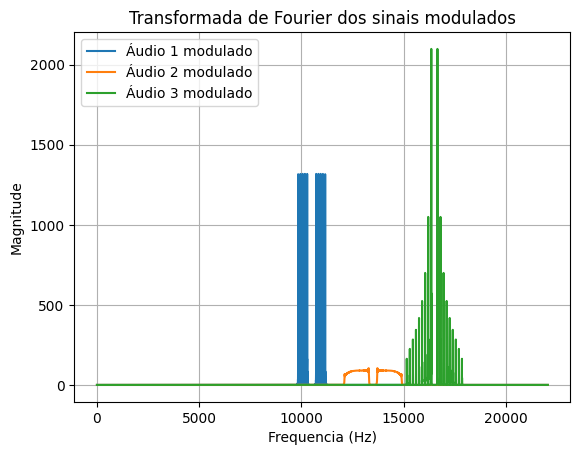

In [33]:
import numpy as np 
import matplotlib.pyplot as plt 

def calculo_FFT(dados, freqAmostra):
    qtd_amostras = len(dados)
    yf = np.abs(np.fft.rfft(dados)) / qtd_amostras
    xf = np.fft.rfftfreq(qtd_amostras, d=1/freqAmostra)
    return xf, yf

tempo = np.linspace(0, duracao, fs*duracao)

portadora1 = np.sin(2*np.pi*10500*tempo)
portadora2 = np.sin(2*np.pi*13500*tempo)
portadora3 = np.sin(2*np.pi*16500*tempo)

audio1_modulado = portadora1*audio1_filtrado
audio2_modulado = portadora2*audio2_filtrado
audio3_modulado = portadora3*audio3_filtrado

xf1_modulado, yf1_modulado = calculo_FFT(audio1_modulado, fs)
xf2_modulado, yf2_modulado = calculo_FFT(audio2_modulado, fs)
xf3_modulado, yf3_modulado = calculo_FFT(audio3_modulado, fs)

plt.figure()
plt.plot(xf1_modulado, yf1_modulado, label="Áudio 1 modulado")
plt.plot(xf2_modulado, yf2_modulado, label="Áudio 2 modulado")
plt.plot(xf3_modulado, yf3_modulado, label="Áudio 3 modulado")
plt.xlabel("Frequencia (Hz)")
plt.ylabel("Magnitude")
plt.title("Transformada de Fourier dos sinais modulados")
plt.grid()
plt.legend()
plt.show()

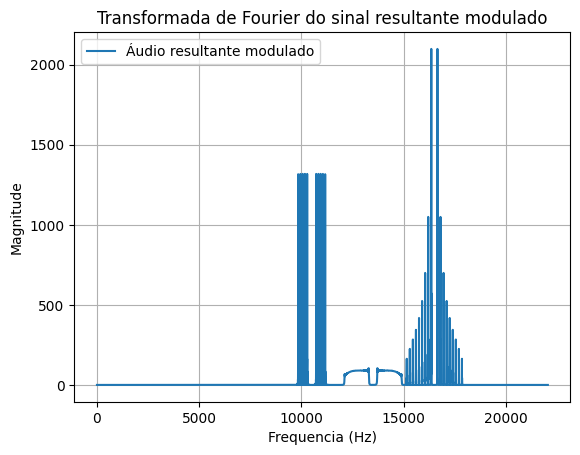

In [34]:
audio_resultante = audio1_modulado + audio2_modulado + audio3_modulado 

xf_res, yf_res = calculo_FFT(audio_resultante, fs)

plt.plot(xf_res, yf_res, label="Áudio resultante modulado")
plt.xlabel("Frequencia (Hz)")
plt.ylabel("Magnitude")
plt.title("Transformada de Fourier do sinal resultante modulado")
plt.grid()
plt.legend()
plt.show()


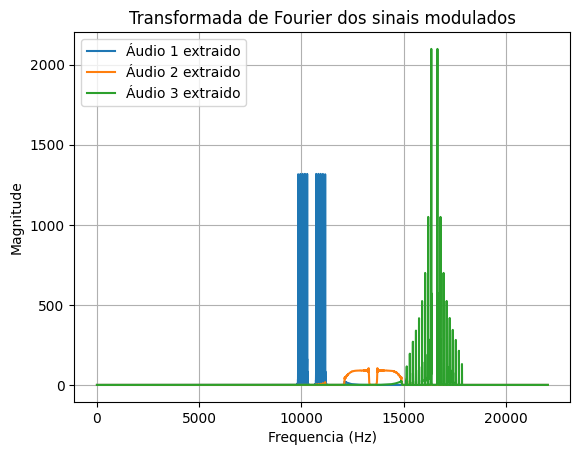

In [35]:
from scipy.signal import freqz

def passa_faixa(sinal, fs,  limite1, limite2, ordem=5):
    nyq = fs / 2
    b, a = signal.butter(ordem, [limite1/nyq, limite2/nyq], btype='bandpass')
    return signal.filtfilt(b, a, sinal) 

audio1_modulado_extraido= passa_faixa(audio_resultante, fs, 9000, 12000)
audio2_modulado_extraido= passa_faixa(audio_resultante, fs, 12000, 15000)
audio3_modulado_extraido= passa_faixa(audio_resultante, fs, 15000, 18000)

xf1_extraido, yf1_extraido = calculo_FFT(audio1_modulado_extraido, fs)
xf2_extraido, yf2_extraido = calculo_FFT(audio2_modulado_extraido, fs)
xf3_extraido, yf3_extraido = calculo_FFT(audio3_modulado_extraido, fs)

plt.figure()
plt.plot(xf1_extraido, yf1_extraido, label="Áudio 1 extraido")
plt.plot(xf2_extraido, yf2_extraido, label="Áudio 2 extraido")
plt.plot(xf3_extraido, yf3_extraido, label="Áudio 3 extraido")
plt.xlabel("Frequencia (Hz)")
plt.ylabel("Magnitude")
plt.title("Transformada de Fourier dos sinais modulados")
plt.grid()
plt.legend()
plt.show()

In [36]:
audio1_demodulado = audio1_modulado_extraido*portadora1
audio2_demodulado = audio2_modulado_extraido*portadora2
audio3_demodulado = audio3_modulado_extraido*portadora3

audio1_demodulado_filtrado = passa_baixa(audio1_demodulado, 1.5e3, fs)
audio2_demodulado_filtrado = passa_baixa(audio2_demodulado, 1.5e3, fs)
audio3_demodulado_filtrado = passa_baixa(audio3_demodulado, 1.5e3, fs)

print("Tocando áudio 1 demodulado:")
sd.play(audio1_demodulado_filtrado, fs)
sd.wait()
print("Áudio 1 demodulado tocado.")

time.sleep(2)

print("Tocando áudio 2 demodulado:")
sd.play(audio2_demodulado_filtrado, fs)
sd.wait()
print("Áudio 2 demodulado tocado.")

time.sleep(2)

print("Tocando áudio 3 demodulado:")
sd.play(audio3_demodulado_filtrado, fs)
sd.wait()
print("Áudio 3 demodulado tocado.")

Tocando áudio 1 demodulado:
Áudio 1 demodulado tocado.
Tocando áudio 2 demodulado:
Áudio 2 demodulado tocado.
Tocando áudio 3 demodulado:
Áudio 3 demodulado tocado.
